In [5]:
import matplotlib.pyplot as plt
import numpy as np
from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error

from pmtwin.config import FD001_SENSORS, Settings
from pmtwin.data import add_rul, load_cmapss

settings = Settings()
train = add_rul(load_cmapss(settings.raw_dir,"FD001").train, settings.rul_cap)
train.head()


,unit,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul,target
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,125


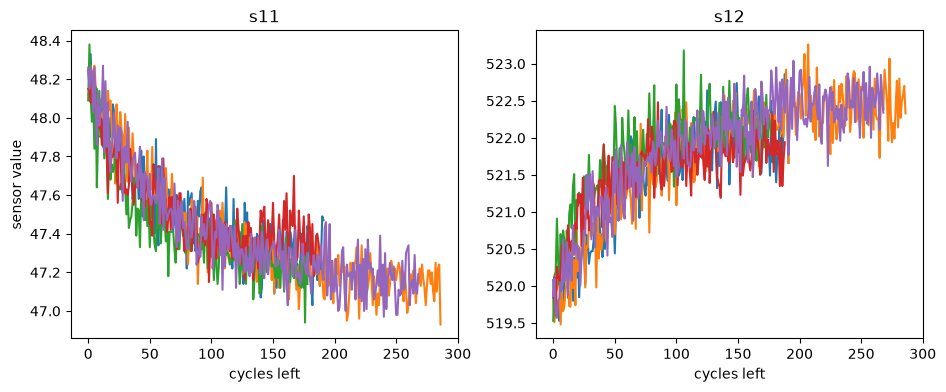

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for unit in [1,2,3,4,5]:
    engine = train[train["unit"]==unit]
    axes[0].plot(engine["rul"], engine["s11"])
    axes[1].plot(engine["rul"], engine["s12"])
axes[0].set_title("s11")
axes[1].set_title("s12")
axes[0].set_xlabel("cycles left")
axes[1].set_xlabel("cycles left")
axes[0].set_ylabel("sensor value")
plt.show()

In [7]:
units = np.random.default_rng(42).permutation(train["unit"].unique())
fit = train[train["unit"].isin(units[:70])]
val = train[train["unit"].isin(units[70:85])]
sensors = list(FD001_SENSORS)

In [8]:
model = LGBMRegressor(random_state=42, verbose=-1)
model.fit(fit[sensors], fit["target"])
print("RMSE:", root_mean_squared_error(val["target"], model.predict(val[sensors])))


RMSE: 17.881702619145145


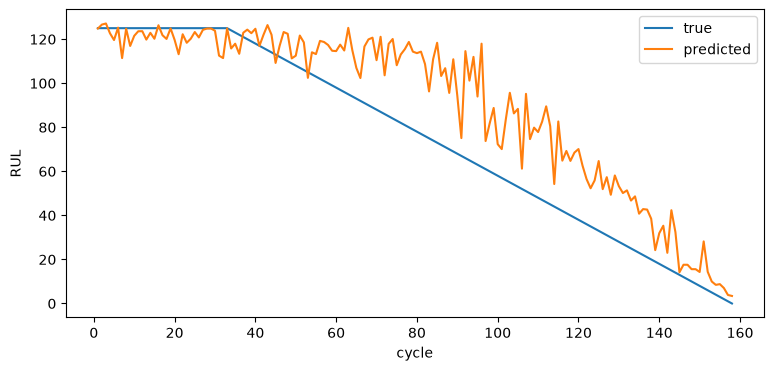

In [9]:
engine = val[val["unit"] == units[70]]
plt.figure(figsize=(9, 4))
plt.plot(engine["cycle"], engine["target"], label="true")
plt.plot(engine["cycle"], model.predict(engine[sensors]), label="predicted")
plt.xlabel("cycle")
plt.ylabel("RUL")
plt.legend()
plt.show()


In [10]:
def add_rolling(frame, window=20):
    rolled = frame.groupby("unit")[sensors].transform(
        lambda s: s.rolling(window, min_periods=1).mean()
    )
    return frame.assign(**{f"{name}_mean": rolled[name] for name in sensors})


fit2, val2 = add_rolling(fit), add_rolling(val)
features = sensors + [f"{name}_mean" for name in sensors]
model2 = LGBMRegressor(random_state=42, verbose=-1)
model2.fit(fit2[features], fit2["target"])
print("RMSE with rolling:", root_mean_squared_error(val2["target"], model2.predict(val2[features])))


RMSE with rolling: 19.10008794861895
